# 02 · Baseline recommenders

**Task:** for each brand, rank all creators so that the ones who will start a **new paid collaboration**
with it in the next months appear at the top.

* *New* means the pair never had a paid collaboration before — predicting repeat partners is easy and not useful.
* Models only see data **before the cutoff** (1 Oct 2018). We evaluate on collaborations that started between
  1 Oct and 31 Dec 2018 (**validation**). January–April 2019 is the **test** period, kept untouched until the
  final model is chosen.

> **Term — baseline:** the simplest reasonable model. A complex model is only worth it if it beats the baselines;
> without them, a number like “recall 0.16” has no meaning.

> **Term — validation vs test:** we may tune and compare models on validation as much as we like. The test set is
> used once, at the very end. If we kept tuning against it, it would stop telling the truth about unseen data.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlrec import baselines as B
from mlrec.data import load
from mlrec.evaluate import evaluate, summarize
from mlrec.split import make_task

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})

inter, creators, brands = load()
task = make_task(inter, "2018-10-01", "2019-01-01")
task.known_pairs_by_brand = {}
for b, c in task.known_pairs:
    task.known_pairs_by_brand.setdefault(b, []).append(c)
eval_brands = sorted(task.positives.brand.unique())
idx = B.Index(task, eval_brands)
followers = creators.set_index("creator_id").followers
pd.Series({"brands evaluated": len(eval_brands), "new collaborations to find": len(task.positives),
           "candidate creators per brand": len(idx.creators)}).to_frame("value")

,value
brands evaluated,6508
new collaborations to find,27069
candidate creators per brand,35232


## How we measure

* **Recall@K** — of all creators a brand really started working with, what share is in our top K?
  Example: a brand had 4 new partners and 2 are in our top 50 → Recall@50 = 0.5.
* **NDCG@50** — like recall, but a hit at position 1 counts more than a hit at position 45
  (each position is discounted by `1 / log2(position + 1)`), normalised to 0–1.
* **Median followers of the top 10** — a check for **popularity bias**: does the model just recommend big accounts?

## The baselines

| model | idea |
|---|---|
| Popularity (all time / last 180 days) | the same list for every brand: creators with the most paid collaborations |
| Organic mentions | creators who already mention this brand without being paid, recent mentions weighted more |
| Brand kNN | *collaborative filtering*: find brands similar to this one (they share creators), recommend creators those brands paid |

> **Term — collaborative filtering:** recommending from the behaviour of others (“brands like you worked with…”),
> without knowing anything about the content itself.
>
> **Term — cosine similarity:** two brands are vectors over creators; cosine measures whether they point in the
> same direction (1 = same pattern, 0 = nothing in common), independent of how big each brand is.

In [2]:
models = {
    "popularity (all time)": B.Popularity(),
    "popularity (last 180d)": B.Popularity(recent_days=180),
    "organic mentions": B.OrganicMentions(),
    "brand kNN": B.BrandKNN(),
}
per_brand = {name: evaluate(task, idx, m.fit(task, idx), followers) for name, m in models.items()}
summary = summarize(per_brand)
summary

,recall@10,recall@50,recall@100,ndcg@50,top10_median_followers
popularity (all time),0.0038,0.0108,0.0202,0.0048,21842.4146
popularity (last 180d),0.0051,0.0174,0.0328,0.0069,19473.6650
organic mentions,0.1180,0.1629,0.1818,0.0986,27456.6805
brand kNN,0.0707,0.1383,0.1829,0.0691,38006.9375


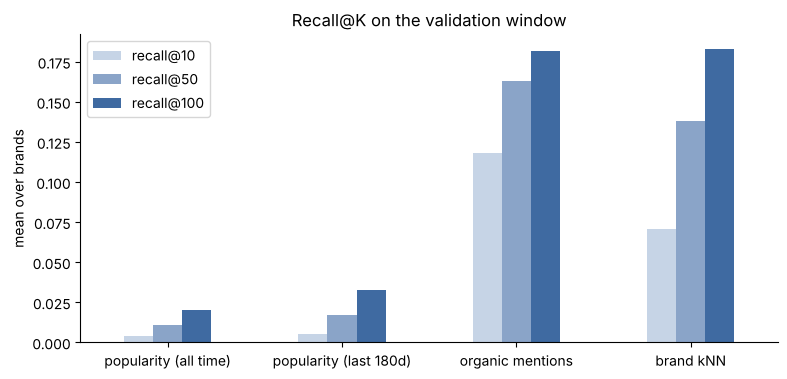

In [3]:
cols = ["recall@10", "recall@50", "recall@100"]
ax = summary[cols].plot.bar(rot=0, color=["#c6d4e6", "#8aa4c8", "#3f6aa1"])
ax.set_ylabel("mean over brands"); ax.set_title("Recall@K on the validation window"); ax.legend(title="");

**Popularity is nearly useless.** There are no universally “good” creators for every brand — personalisation is
necessary. **Organic mentions** is the strongest single signal; **brand kNN** catches up deeper in the list.

## Who does each model work for?

An average can hide that a model is great for big brands and poor for small ones. We split brands by how much
history they have (distinct creators that mentioned them before the cutoff).

> **Term — cold start:** a brand with no history at all. Collaborative filtering has nothing to work with.
> In this dataset almost every brand has been mentioned before, so true cold start is rare (see counts).

,popularity (all time),popularity (last 180d),organic mentions,brand kNN,brands
bucket,,,,,
cold (0),0.000,0.005,0.005,0.005,36
1-9,0.009,0.018,0.162,0.175,1753
10-99,0.012,0.017,0.172,0.136,3946
100+,0.011,0.018,0.125,0.075,773


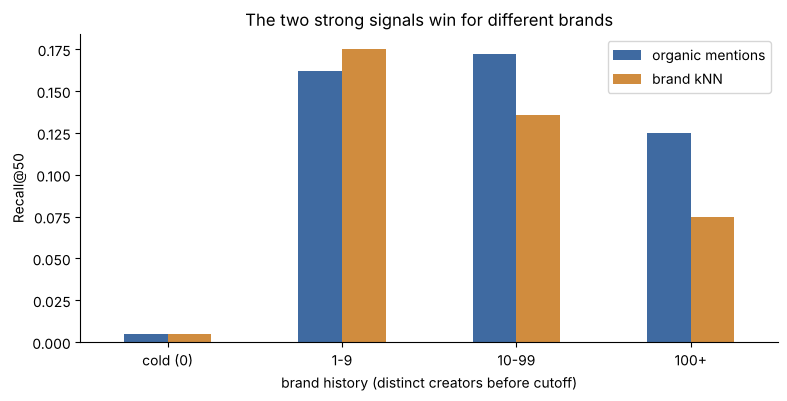

In [4]:
by_bucket = pd.concat({n: d.groupby("bucket", observed=True)["recall@50"].mean() for n, d in per_brand.items()}, axis=1)
counts = per_brand["organic mentions"].bucket.value_counts().sort_index().rename("brands")
display(by_bucket.join(counts).round(3))
ax = by_bucket[["organic mentions", "brand kNN"]].plot.bar(rot=0, color=["#3f6aa1", "#d08c3e"])
ax.set_ylabel("Recall@50"); ax.set_xlabel("brand history (distinct creators before cutoff)")
ax.set_title("The two strong signals win for different brands");

kNN is better for brands with little history (1–9 creators); organic mentions are better for brands with more.
**They are complementary** — the argument for a model that learns how to combine them (notebook 03).

## Popularity bias

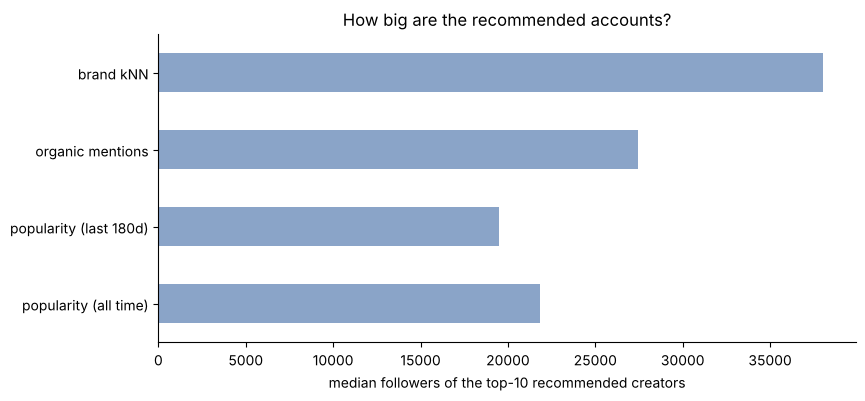

In [5]:
ax = summary["top10_median_followers"].plot.barh(color="#8aa4c8")
ax.set_xlabel("median followers of the top-10 recommended creators"); ax.set_title("How big are the recommended accounts?");

kNN recommends noticeably larger accounts. Not necessarily wrong, but if every brand gets the same big names,
smaller creators never get a chance and campaigns get expensive. We will keep tracking this for every model.

## Takeaways

1. The task needs personalisation — popularity scores ≈ 0.
2. **Organic mentions** is a strong, explainable signal (~12% of future partners in the top 10 out of ~35k creators).
3. **Brand kNN** complements it and helps brands with little history.
4. Next: a **learning-to-rank** model (LightGBM) that combines these signals with niche match, recency,
   account size and engagement — it must beat the best baseline in every brand group, not just on average.